# Shiro Twin: de la Q-table a la red, el agente con estado continuo (DQN)

**Taller 3 · 3.er corte (Aprendizaje por Refuerzo) · Aprendizaje de Máquina 26-2 · Grupo Shiro** · Universidad Sergio Arboleda

## Qué componente de Shiro se construye aquí
El agente de Shiro con **estado continuo**: una red neuronal reemplaza a la Q-table. Es la evolución del MDP del Taller 1
(resuelto con iteración de valor) y de Q-learning del Taller 2 (aprendido con experiencia).

## Qué decisiones de arquitectura dependen de este resultado
1. **¿La red acorta el arranque en frío?** En el Taller 2, Q-learning no llegó al 90 % de acierto ni con 15.000 días
   simulados (≈ 41 años).
2. **¿La hora exacta y el consumo continuo mejoran la decisión?** La tabla solo veía la franja (bloques de 6 horas).
3. **¿Qué trucos de estabilidad son imprescindibles con nuestros datos?** Se quitan, uno por vez, la memoria de
   experiencias y la red objetivo.
4. **Qué agente usa la consola del parcial.**

## Reglas
- Mismos datos, tarifa, ΔE, λ y partición temporal que los talleres 1 y 2. El agente aprende con enero–abril y se evalúa
  en mayo con la cuenta real.
- 5 semillas por configuración. La red está escrita en **NumPy** (sin librerías de aprendizaje profundo) para que sus
  pesos puedan correr en la consola del parcial.
- Ninguna cifra está escrita a mano: todas van a `cifras.json`.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")
%matplotlib inline

RS, SEMILLAS = 42, [42, 43, 44, 45, 46]
CORTE = pd.Timestamp("2016-04-30")
UMBRAL, NIVEL_BAJO, HORA_TIPO = 200, 60, 8
R_PUNTA, F_DESPL, LAMBDA, LAMBDA_EX = 1.5, 0.40, 0.005, 0.02
GAMMA, THETA = 0.95, 1e-6
# Q-learning tabular recomendado en el Taller 2
ALPHA_REC, N_EP_REC, EPS0, EPS_MIN, DECAY, CADA = "1/N^0.6", 15000, 1.0, 0.01, 0.999, 50
# DQN
N_EP_DQN, OCULTA, LR, LOTE, CAPACIDAD, CALENTAMIENTO, SINCRONIA = 1500, 64, 1e-3, 64, 20000, 500, 500
EPS_FIN_DQN, FRAC_EPS = 0.05, 0.5
CONTROLES = [10, 20, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 5000, 10000, 15000]   # días en que se mide mayo

RUTA_CSV = Path("../../data set/energydata_complete.csv")
RUTA_T1, RUTA_T2 = Path("../Taller_1_RL_MDP/cifras.json"), Path("../Taller_2_QLearning/cifras.json")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False})
AZUL = "#1F3864"; PALETA = ["#1F3864", "#C55A11", "#2E75B6", "#548235", "#7F6000", "#8C8C8C"]
ACCIONES = ["No actuar", "Aplazar", "Ejecutar"]
CIFRAS = {}
def es(x, dec=1):
    s = f"{abs(x):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return ("\u2212" if (x < 0 and round(abs(x), dec) != 0) else "") + s
def reg(k, v, t):
    if isinstance(v, (np.floating, np.integer)):
        v = v.item()
    CIFRAS[k] = {"valor": v, "texto": t}
print("Listo.")

Listo.


## PASO 1 · Datos (los de los talleres 1 y 2)

In [2]:
df = pd.read_csv(RUTA_CSV, parse_dates=["date"])
df["dia"] = df["date"].dt.normalize(); df["hora"] = df["date"].dt.hour
lect = df.groupby("dia").size(); DIAS = lect[lect == 144].index
d = df[df["dia"].isin(DIAS)].copy(); d["exceso"] = (d["Appliances"] - UMBRAL).clip(lower=0)
H = (d.groupby(["dia", "hora"]).agg(media=("Appliances", "mean"), wh=("Appliances", "sum"), exceso=("exceso", "sum"))
       .reset_index().sort_values(["dia", "hora"]).reset_index(drop=True))
H["ts"] = H["dia"] + pd.to_timedelta(H["hora"], unit="h"); H["train"] = H["dia"] <= CORTE; H["franja"] = H["hora"] // 6
DIAS_TR = [x for x in DIAS if x <= CORTE]; DIAS_TE = [x for x in DIAS if x > CORTE]
assert len(df) == 19735 and len(DIAS) == 136 and len(DIAS_TR) == 110 and len(DIAS_TE) == 26
print(f"{len(DIAS)} días completos → {len(H)} horas (entrenamiento {H.train.sum()}, mayo {(~H.train).sum()})")
reg("n_dias_tr", len(DIAS_TR), es(len(DIAS_TR), 0)); reg("n_dias_te", len(DIAS_TE), es(len(DIAS_TE), 0))

136 días completos → 3264 horas (entrenamiento 2640, mayo 624)


## PASO 2 · Dos formas de ver el estado

- **Tabla (talleres 1 y 2):** tipo de día × franja × nivel × carga pendiente = 40 estados discretos.
- **Vector continuo (este taller), 9 números que Shiro conoce a esa hora:**
  - hora como seno y coseno;
  - consumo de la hora en curso y de la anterior (log, estandarizado);
  - **margen de K-Means** hacia el día de carga alta, calculado con la curva vista hasta la hora anterior (0 antes de
    las 8 h);
  - tarifa vigente;
  - carga pendiente y horas que lleva esperando;
  - nivel alto (media > 200 Wh), que es lo que permite aplazar.

In [3]:
NIVEL_DIA = H.pivot(index="dia", columns="hora", values="media")
km = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(NIVEL_DIA.loc[DIAS_TR].values)
C = km.cluster_centers_; ALTO = int(np.argmax(C.sum(1)))
def tipo_y_margen(curva, h):
    if h < HORA_TIPO:
        return 0, 0.0
    dd = np.sqrt(((C[:, :h] - curva[:h]) ** 2).sum(1)); d_alto, d_norm = dd[ALTO], dd[1 - ALTO]
    return int(np.argmin(dd) == ALTO), float((d_norm - d_alto) / (d_norm + d_alto + 1e-9))
tm = [tipo_y_margen(NIVEL_DIA.loc[a].values, b) for a, b in zip(H.dia, H.hora)]
H["tipo"] = [t for t, _ in tm]; H["margen"] = [m for _, m in tm]
H["nivel_umbral"] = np.select([H["media"] < NIVEL_BAJO, H["media"] <= UMBRAL], [0, 1], 2)
H["x_umbral"] = H["tipo"].astype(str) + "-" + H["franja"].astype(str) + "-" + H["nivel_umbral"].astype(str)
H["logw"] = np.log(H["wh"]); H["logw_prev"] = H["logw"].shift(1).fillna(H["logw"].iloc[0])
MU, SD = H.loc[H.train, "logw"].mean(), H.loc[H.train, "logw"].std()
TR, TE = H[H.train].reset_index(drop=True), H[~H.train].reset_index(drop=True)
TIPO_N = {0: "normal", 1: "carga alta"}; FRANJA_N = {0: "madrugada", 1: "mañana", 2: "tarde", 3: "noche"}; NIVEL_N = {0: "bajo", 1: "medio", 2: "alto"}
def partes(x): return tuple(int(v) for v in x.split("-")[:3])
def describir(s):
    t, f, n = partes(s); return f"{TIPO_N[t]} · {FRANJA_N[f]} · {NIVEL_N[n]}" + (" · pendiente" if s.endswith("-1") and s.count("-") == 3 else "")
print(f"Margen de K-Means en entrenamiento: de {TR.margen.min():.2f} a {TR.margen.max():.2f}")
reg("n_rasgos", 9, "9")

Margen de K-Means en entrenamiento: de -0.84 a 0.60


## PASO 3 · El MDP de referencia (Taller 1) y los entornos

La iteración de valor da π\*, la respuesta correcta en el mundo de 40 estados. Se comprueba que el entorno reproduzca el
Taller 1 (anclas) antes de entrenar nada.

**Recompensa centrada (decisión de diseño de este taller).** El costo de lo que consume la casa (−tarifa × energía) no
depende de lo que decida Shiro: es igual con cualquier política. Quitarlo de la recompensa **no cambia la política
óptima**, pero elimina el ruido que en el Taller 2 enterraba las brechas entre acciones. El agente aprende solo lo que su
acción cambia:
- aplazar: + sobrecosto evitado − valle reservado − λ;
- ejecutar: − sobrecosto de la tarifa vigente;
- esperar con una carga pendiente: − λ.

In [4]:
class MDP:
    def __init__(self, Hs, r_punta=R_PUNTA, lam=LAMBDA):
        col = "x_umbral"; self.lam, self.r_punta = lam, r_punta
        self.DE = F_DESPL * TR.loc[TR.nivel_umbral == 2, "exceso"].mean()
        self.X = sorted(Hs[col].unique()); self.xi = {x: i for i, x in enumerate(self.X)}
        nX = len(self.X); self.nX, self.nS = nX, 2 * nX; self.S = [f"{x}-{p}" for x in self.X for p in (0, 1)]
        sig = Hs[[col, "ts"]].shift(-1); ok = (sig["ts"] - Hs["ts"]) == pd.Timedelta(hours=1)
        self.P = np.zeros((nX, nX))
        for a_, b_ in zip(Hs.loc[ok, col], sig.loc[ok, col]):
            self.P[self.xi[a_], self.xi[b_]] += 1
        self.P /= self.P.sum(1, keepdims=True)
        self.E = Hs.groupby(col)["wh"].mean().reindex(self.X).values / 1000
        self.F = np.array([partes(x)[1] for x in self.X]); self.N = np.array([partes(x)[2] for x in self.X])
        self.TAR = np.where(self.F == 0, 1.0, r_punta); de = self.DE / 1000
        self.VALID = np.zeros((self.nS, 3), bool); self.P2 = np.zeros((self.nS, 3), int); self.R = np.full((self.nS, 3), np.nan)
        for i in range(nX):
            for p in (0, 1):
                s = 2 * i + p; tar, e = self.TAR[i], self.E[i]
                self.VALID[s] = [True, self.N[i] == 2 and p == 0, p == 1]; self.P2[s] = [p, 1, 0]
                costo = [tar * e, tar * (e - de) + 1.0 * de, tar * e + (tar - 1.0) * de]
                for a in range(3):
                    if self.VALID[s, a]:
                        self.R[s, a] = -costo[a] - lam * self.P2[s, a]
        self.decision = np.flatnonzero(self.VALID.sum(1) > 1)

def iteracion_valor(m, gamma=GAMMA, theta=THETA):
    V = np.zeros(m.nS); it = 0; xs = np.repeat(np.arange(m.nX), 2)
    while True:
        it += 1
        EV = np.stack([m.P @ V[0::2], m.P @ V[1::2]], 1)
        Q = np.where(m.VALID, m.R + gamma * EV[xs[:, None], m.P2], -np.inf); Vn = Q.max(1)
        if np.abs(Vn - V).max() < theta:
            return Vn, Q, it
        V = Vn

def politica_de(Q, VALID, visitas=None):
    Qm = np.where(VALID if visitas is None else (VALID & (visitas > 0)), Q, -np.inf)
    mejor = Qm.max(1); pol = Qm.argmax(1); pol[(Qm[:, 0] >= mejor - 1e-12) | ~np.isfinite(mejor)] = 0
    return pol

def repetir(pol, m, tramo, r_punta=R_PUNTA):
    p = 0; filas = []; DE = m.DE
    for x, f, wh, dia in tramo[["x_umbral", "franja", "wh", "dia"]].itertuples(index=False):
        s = m.xi.get(x); a = 0
        if s is not None:
            s = 2 * s + p; a = int(pol[s]) if m.VALID[s, int(pol[s])] else 0
        tar = 1.0 if f == 0 else r_punta; e = wh + (-DE if a == 1 else (DE if a == 2 else 0))
        p = 1 if a == 1 else (0 if a == 2 else p); filas.append((dia, tar * e / 1000, p, int(a == 1)))
    if p == 1:
        dia, c, e_, ap = filas[-1]; filas[-1] = (dia, c + (1.0 if tramo.franja.iloc[-1] == 0 else r_punta) * DE / 1000, e_, ap)
    return pd.DataFrame(filas, columns=["dia", "costo", "espera", "aplaza"]).groupby("dia").sum()

BASE_TE = None
def resumen(dd, tramo=None, lam=LAMBDA):
    global BASE_TE
    if tramo is None or tramo is TE:
        if BASE_TE is None:
            BASE_TE = repetir(np.zeros(mU.nS, int), mU, TE)
        base = BASE_TE
    else:
        base = repetir(np.zeros(mU.nS, int), mU, tramo)
    return {"ahorro": (1 - dd.costo.sum() / base.costo.sum()) * 100, "espera": dd.espera.mean(), "aplaz": dd.aplaza.mean(),
            "objetivo": (dd.costo + lam * dd.espera).mean(), "diarios": dd}

mU = MDP(TR); _, QSTAR, it = iteracion_valor(mU); piU = politica_de(QSTAR, mU.VALID)
r_pi = resumen(repetir(piU, mU, TE)); AHORRO_PI = r_pi["ahorro"]
t1 = json.loads(RUTA_T1.read_text(encoding="utf-8"))["cifras"]
anclas = {"ahorro_opt_te": r_pi["ahorro"], "espera_opt_te": r_pi["espera"], "n_estados": mU.nS, "iteraciones": it, "DE": mU.DE}
for k_, v in anclas.items():
    assert abs(t1[k_]["valor"] - v) < 1e-6, f"Ancla {k_}"
print(f"Anclas con el Taller 1: {len(anclas)}/{len(anclas)} coinciden · π* en mayo ahorra {AHORRO_PI:.3f} % con {r_pi['espera']:.2f} h/día de espera")
reg("vi_ahorro_te", AHORRO_PI, es(AHORRO_PI, 2) + " %"); reg("vi_espera_te", r_pi["espera"], es(r_pi["espera"], 1) + " h/día")
reg("DE", mU.DE, es(mU.DE, 0) + " Wh"); reg("n_estados", mU.nS, es(mU.nS, 0))
_, QX, _ = iteracion_valor(MDP(TR, lam=LAMBDA_EX)); piX = politica_de(QX, mU.VALID)
r_pix = resumen(repetir(piX, MDP(TR, lam=LAMBDA_EX), TE), lam=LAMBDA_EX)
reg("vi_ex_ahorro_te", r_pix["ahorro"], es(r_pix["ahorro"], 2) + " %"); reg("vi_ex_espera_te", r_pix["espera"], es(r_pix["espera"], 1) + " h/día")

Anclas con el Taller 1: 5/5 coinciden · π* en mayo ahorra 0.594 % con 7.15 h/día de espera


In [5]:
class EntornoReplica:
    """Días reales en orden, sin reiniciar a medianoche (el del Taller 2)."""
    def __init__(self, m, tramo):
        self.m = m; self.xi = np.array([m.xi[x] for x in tramo["x_umbral"]]); self.f = tramo["franja"].values
        self.e = tramo["wh"].values / 1000; self.n = len(tramo); self.dias = self.n // 24
    def reset(self, rng):
        return 0
    def paso(self, i, p, a, rng):
        tar = 1.0 if self.f[i] == 0 else self.m.r_punta; j = i + 1 if i + 1 < self.n else 0
        return tar, self.e[i], j, int(self.xi[j])

def entrenar_ql(m, entorno, alpha=ALPHA_REC, gamma=GAMMA, n_ep=N_EP_REC, semilla=RS, centrada=False):
    """Q-learning tabular del Taller 2 (misma regla y semillas). centrada=True quita el costo que no depende de la acción."""
    rng = np.random.default_rng(semilla); nS = m.nS; Q = np.zeros((nS, 3)); N = np.zeros((nS, 3), int)
    validas = [np.flatnonzero(m.VALID[s]).tolist() for s in range(nS)]; de, lam = m.DE / 1000, m.lam
    alfa_fija = not isinstance(alpha, str); eps = EPS0; h_g, h_eps, h_cap = [], [], {}
    pos = entorno.reset(rng); x = int(entorno.xi[pos]); p = 0
    for ep in range(n_ep):
        tot = ref = 0.0
        for t in range(24):
            s = 2 * x + p; va = validas[s]
            a = va[int(rng.random() * len(va))] if rng.random() < eps else max(va, key=lambda a_: Q[s, a_])
            tar, e, pos2, x2 = entorno.paso(pos, p, a, rng)
            if a == 0:
                c = tar * e; p2 = p
            elif a == 1:
                c = tar * (e - de) + 1.0 * de; p2 = 1
            else:
                c = tar * e + (tar - 1.0) * de; p2 = 0
            r = -c - lam * p2 + (tar * e if centrada else 0.0)
            s2 = 2 * x2 + p2; q2 = max(Q[s2, a_] for a_ in validas[s2]); N[s, a] += 1
            al = alpha if alfa_fija else 1.0 / N[s, a] ** 0.6
            Q[s, a] += al * (r + gamma * q2 - Q[s, a]); tot += r; ref += tar * e; x, p, pos = x2, p2, pos2
        h_g.append(tot if centrada else tot + ref); h_eps.append(eps); eps = max(EPS_MIN, eps * DECAY)
        if (ep + 1) in CONTROLES:
            h_cap[ep + 1] = resumen(repetir(politica_de(Q, m.VALID, N), m, TE))["ahorro"] / AHORRO_PI * 100
    return {"Q": Q, "N": N, "pol": politica_de(Q, m.VALID, N), "g": np.array(h_g), "eps": np.array(h_eps), "cap": h_cap}
ENV_R = EntornoReplica(mU, TR)
print("Entornos listos.")

Entornos listos.


## PASO 4 · La red: DQN escrito en NumPy

- **Red:** 9 entradas → 64 → 64 → 3 salidas (Q de no actuar, aplazar y ejecutar), ReLU, pérdida de Huber, Adam
  (tasa 10⁻³) y recorte del gradiente. Las acciones inválidas se enmascaran.
- **Memoria de experiencias** (*experience replay*): 20.000 transiciones; cada paso entrena con un lote de 64 tomado
  **al azar**.
- **Red objetivo:** una copia congelada que calcula el objetivo r + γ·max Q(s′) y se sincroniza cada 500 actualizaciones.
- **Double DQN** (variante): la red principal elige la acción siguiente y la objetivo la evalúa, lo que reduce la
  sobreestimación que el Taller 2 midió en +0,25.
- ε baja de 1,0 a 0,05 en la primera mitad del entrenamiento.

In [6]:
def rasgos_tramo(tramo):
    h = tramo["hora"].values
    return {"sin": np.sin(2 * np.pi * h / 24), "cos": np.cos(2 * np.pi * h / 24), "w": (tramo["logw"].values - MU) / SD,
            "wp": (tramo["logw_prev"].values - MU) / SD, "m": tramo["margen"].values, "punta": (tramo["franja"].values != 0).astype(float),
            "alto": (tramo["nivel_umbral"].values == 2).astype(float), "tar": np.where(tramo["franja"].values == 0, 1.0, R_PUNTA),
            "e": tramo["wh"].values / 1000, "n": len(tramo), "dia": tramo["dia"].values}

def vec(R_, i, p, hp):
    return np.array([R_["sin"][i], R_["cos"][i], R_["w"][i], R_["wp"][i], R_["m"][i], R_["punta"][i], p, hp / 24.0, R_["alto"][i]])

def mascara(R_, i, p):
    return np.array([True, R_["alto"][i] == 1 and p == 0, p == 1])

class Red:
    def __init__(self, n_in, n_out, oculta, rng):
        he = lambda a, b: rng.normal(0, np.sqrt(2 / a), (a, b))
        self.p = {"W1": he(n_in, oculta), "b1": np.zeros(oculta), "W2": he(oculta, oculta), "b2": np.zeros(oculta),
                  "W3": rng.normal(0, 0.01, (oculta, n_out)), "b3": np.zeros(n_out)}
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}; self.v = {k: np.zeros_like(v) for k, v in self.p.items()}; self.t = 0
    def q(self, X):
        a1 = np.maximum(0, X @ self.p["W1"] + self.p["b1"]); a2 = np.maximum(0, a1 @ self.p["W2"] + self.p["b2"])
        return a2 @ self.p["W3"] + self.p["b3"], (X, a1, a2)
    def paso(self, cache, dq, lr=LR, clip=10.0):
        X, a1, a2 = cache; g = {"W3": a2.T @ dq, "b3": dq.sum(0)}; d2 = (dq @ self.p["W3"].T) * (a2 > 0)
        g["W2"] = a1.T @ d2; g["b2"] = d2.sum(0); d1 = (d2 @ self.p["W2"].T) * (a1 > 0); g["W1"] = X.T @ d1; g["b1"] = d1.sum(0)
        norma = np.sqrt(sum((v ** 2).sum() for v in g.values()))
        if norma > clip:
            g = {k: v * clip / norma for k, v in g.items()}
        self.t += 1
        for k in self.p:
            self.m[k] = 0.9 * self.m[k] + 0.1 * g[k]; self.v[k] = 0.999 * self.v[k] + 0.001 * g[k] ** 2
            mh = self.m[k] / (1 - 0.9 ** self.t); vh = self.v[k] / (1 - 0.999 ** self.t)
            self.p[k] -= lr * mh / (np.sqrt(vh) + 1e-8)
    def copia(self):
        r = Red.__new__(Red); r.p = {k: v.copy() for k, v in self.p.items()}; return r

RTR, RTE = rasgos_tramo(TR), rasgos_tramo(TE); DE_KWH = mU.DE / 1000

def recompensa(tar, a, p, lam):
    """Recompensa centrada: solo lo que cambia la acción (el costo de lo que consume la casa no depende de Shiro)."""
    if a == 1:
        return (tar - 1.0) * DE_KWH - lam, 1
    if a == 2:
        return -(tar - 1.0) * DE_KWH, 0
    return -lam * p, p

def actuar(red, R_, i, p, hp):
    q, _ = red.q(vec(R_, i, p, hp)[None, :]); q = q[0]; mk = mascara(R_, i, p); q[~mk] = -np.inf
    a = int(np.argmax(q)); return 0 if q[0] >= q[a] - 1e-12 else a

def repetir_red(red, R_=None):
    R_ = RTE if R_ is None else R_
    p = hp = 0; filas = []
    for i in range(R_["n"]):
        a = actuar(red, R_, i, p, hp); tar = R_["tar"][i]
        e = R_["e"][i] + (-DE_KWH if a == 1 else (DE_KWH if a == 2 else 0))
        hp = 1 if a == 1 else (0 if a == 2 else (hp + 1 if p == 1 else 0)); p = 1 if a == 1 else (0 if a == 2 else p)
        filas.append((R_["dia"][i], tar * e, p, int(a == 1)))
    if p == 1:
        dia, c, e_, ap = filas[-1]; filas[-1] = (dia, c + R_["tar"][-1] * DE_KWH, e_, ap)
    return pd.DataFrame(filas, columns=["dia", "costo", "espera", "aplaza"]).groupby("dia").sum()

def entrenar_dqn(n_ep=N_EP_DQN, semilla=RS, gamma=GAMMA, lam=LAMBDA, replay=True, objetivo=True, doble=False, R_=None):
    R_ = RTR if R_ is None else R_
    rng = np.random.default_rng(semilla); red = Red(9, 3, OCULTA, rng); tgt = red.copia()
    S = np.zeros((CAPACIDAD, 9)); A = np.zeros(CAPACIDAD, int); Rw = np.zeros(CAPACIDAD); S2 = np.zeros((CAPACIDAD, 9))
    M2 = np.zeros((CAPACIDAD, 3), bool); n = cab = act = 0; h = {"g": [], "eps": [], "loss": [], "qmed": [], "cap": {}}
    sonda = np.stack([vec(R_, i, p, hp) for i, p, hp in ((7, 0, 0), (11, 0, 0), (17, 0, 0), (20, 1, 3), (2, 1, 5), (14, 1, 6))])
    i = p = hp = 0
    for ep in range(n_ep):
        eps = max(EPS_FIN_DQN, 1 - (1 - EPS_FIN_DQN) * ep / (FRAC_EPS * n_ep)); tot = 0.0; perdidas = []
        for t in range(24):
            mk = mascara(R_, i, p); s = vec(R_, i, p, hp)
            if rng.random() < eps:
                va = np.flatnonzero(mk); a = int(va[int(rng.random() * len(va))])
            else:
                a = actuar(red, R_, i, p, hp)
            r, p2 = recompensa(R_["tar"][i], a, p, lam)
            hp2 = 1 if a == 1 else (0 if a == 2 else (hp + 1 if p == 1 else 0))
            j = i + 1 if i + 1 < R_["n"] else 0
            S[cab], A[cab], Rw[cab], S2[cab], M2[cab] = s, a, r, vec(R_, j, p2, hp2), mascara(R_, j, p2)
            cab = (cab + 1) % CAPACIDAD; n = min(n + 1, CAPACIDAD); tot += r
            if n >= max(CALENTAMIENTO, LOTE):
                idx = rng.integers(0, n, LOTE) if replay else (np.arange(cab - LOTE, cab) % CAPACIDAD)
                q_sig, _ = (tgt if objetivo else red).q(S2[idx]); q_sig = np.where(M2[idx], q_sig, -np.inf)
                if doble:
                    q_on, _ = red.q(S2[idx]); q_on = np.where(M2[idx], q_on, -np.inf)
                    v_sig = q_sig[np.arange(LOTE), q_on.argmax(1)]
                else:
                    v_sig = q_sig.max(1)
                y = Rw[idx] + gamma * v_sig
                q, cache = red.q(S[idx]); delta = q[np.arange(LOTE), A[idx]] - y
                dq = np.zeros_like(q); dq[np.arange(LOTE), A[idx]] = np.clip(delta, -1, 1) / LOTE
                red.paso(cache, dq); act += 1; perdidas.append(float(np.mean(np.where(np.abs(delta) < 1, 0.5 * delta ** 2, np.abs(delta) - 0.5))))
                if objetivo and act % SINCRONIA == 0:
                    tgt = red.copia()
            i, p, hp = j, p2, hp2
        h["g"].append(tot); h["eps"].append(eps); h["loss"].append(np.mean(perdidas) if perdidas else np.nan)
        h["qmed"].append(float(np.abs(red.q(sonda)[0]).mean()))
        if (ep + 1) in CONTROLES:
            h["cap"][ep + 1] = resumen(repetir_red(red), lam=lam)["ahorro"]
    h["red"] = red
    return h

def correr_dqn(etiqueta, **kw):
    t0 = time.time(); cor = [entrenar_dqn(semilla=s_, **kw) for s_ in SEMILLAS]
    ev = [resumen(repetir_red(c["red"]), lam=kw.get("lam", LAMBDA)) for c in cor]
    ref = AHORRO_PI if kw.get("lam", LAMBDA) == LAMBDA else r_pix["ahorro"]
    cap = [e["ahorro"] / ref * 100 for e in ev]
    print(f"  {etiqueta:<34} {time.time() - t0:5.1f} s · ahorro mayo {np.mean([e['ahorro'] for e in ev]):.3f} % · capturado de π* "
          f"{np.mean(cap):5.1f} % (rango {min(cap):.0f}–{max(cap):.0f}) · espera {np.mean([e['espera'] for e in ev]):.1f} h/día")
    return cor, ev
print("DQN listo.")

DQN listo.


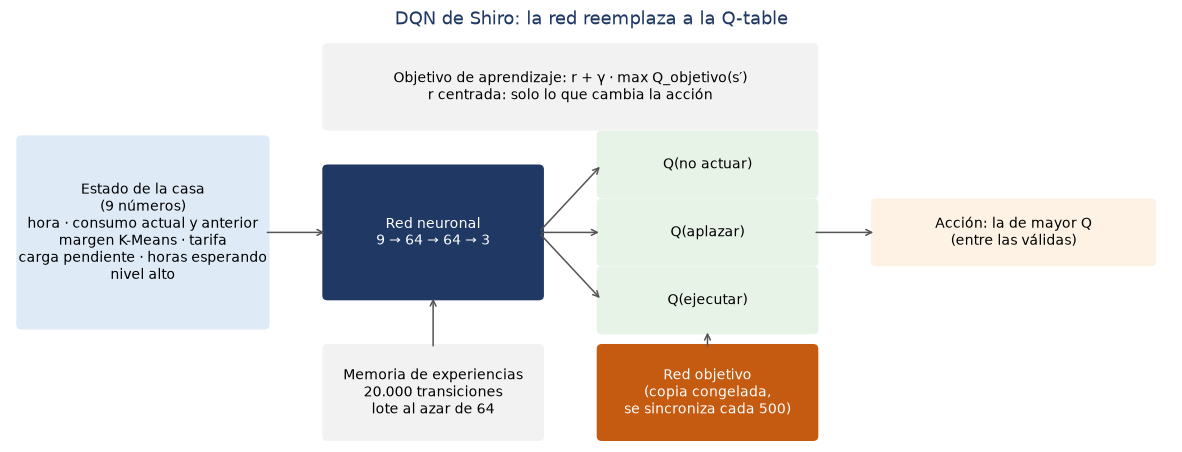

In [7]:
# Esquema del DQN (para el video y el documento)
fig, ax = plt.subplots(figsize=(11, 4.2)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 4.2)
def caja(x, y, w, h, txt, col):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=col, ec="none"))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=9, color="white" if col in (AZUL, "#C55A11") else "black")
caja(0.1, 1.2, 2.3, 1.9, "Estado de la casa\n(9 números)\nhora · consumo actual y anterior\nmargen K-Means · tarifa\ncarga pendiente · horas esperando\nnivel alto", "#DEEAF6")
caja(3.0, 1.5, 2.0, 1.3, "Red neuronal\n9 → 64 → 64 → 3", AZUL)
caja(5.6, 2.55, 2.0, 0.6, "Q(no actuar)", "#E8F3E8"); caja(5.6, 1.85, 2.0, 0.6, "Q(aplazar)", "#E8F3E8"); caja(5.6, 1.15, 2.0, 0.6, "Q(ejecutar)", "#E8F3E8")
caja(8.2, 1.85, 2.6, 0.6, "Acción: la de mayor Q\n(entre las válidas)", "#FDF2E3")
caja(3.0, 0.05, 2.0, 0.9, "Memoria de experiencias\n20.000 transiciones\nlote al azar de 64", "#F2F2F2")
caja(5.6, 0.05, 2.0, 0.9, "Red objetivo\n(copia congelada,\nse sincroniza cada 500)", "#C55A11")
caja(3.0, 3.25, 4.6, 0.8, "Objetivo de aprendizaje: r + γ · max Q_objetivo(s′)\nr centrada: solo lo que cambia la acción", "#F2F2F2")
for (x1, y1, x2, y2) in ((2.4, 2.15, 3.0, 2.15), (5.0, 2.15, 5.6, 2.85), (5.0, 2.15, 5.6, 2.15), (5.0, 2.15, 5.6, 1.45), (7.6, 2.15, 8.2, 2.15),
                         (4.0, 0.95, 4.0, 1.5), (6.6, 0.95, 6.6, 1.15)):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_title("DQN de Shiro: la red reemplaza a la Q-table", fontsize=12, color=AZUL)
fig.tight_layout(); fig.savefig(FIG / "T0_esquema_dqn.png"); plt.show()

## E1 · La batalla: DQN frente a π\* (Taller 1) y frente a Q-learning (Taller 2)

Q-learning se vuelve a entrenar con el código y las semillas del Taller 2: debe reproducir su ahorro en mayo (ancla).

Ancla con el Taller 2: Q-learning recomendado reproduce su ahorro en mayo (0.531 %)


  DQN                                115.3 s · ahorro mayo 0.575 % · capturado de π*  96.8 % (rango 89–100) · espera 6.7 h/día


  Double DQN                         141.3 s · ahorro mayo 0.525 % · capturado de π*  88.4 % (rango 74–100) · espera 5.9 h/día
DQN (semilla mediana) menos π*: -0.0000 kWh-eq/día (IC -0.0000 a 0.0000) → ¿se distingue? no
DQN (semilla mediana) menos Q-learning recomendado: -0.0008 kWh-eq/día (IC -0.0558 a 0.0525) → ¿se distingue? no


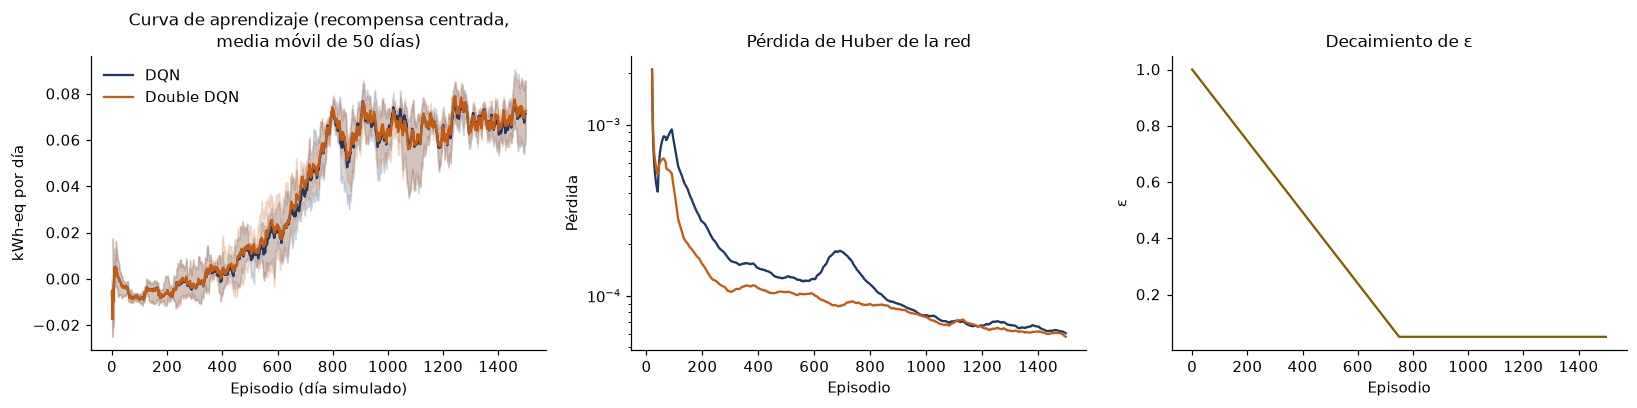

In [8]:
TABLA = []
QL = [entrenar_ql(mU, ENV_R, semilla=s_) for s_ in SEMILLAS]
ev_ql = [resumen(repetir(c["pol"], mU, TE)) for c in QL]
t2 = json.loads(RUTA_T2.read_text(encoding="utf-8"))["cifras"]
assert abs(np.mean([e["ahorro"] for e in ev_ql]) - t2["base_ahorro"]["valor"]) < 1e-9, "Ancla con el Taller 2"
print(f"Ancla con el Taller 2: Q-learning recomendado reproduce su ahorro en mayo ({np.mean([e['ahorro'] for e in ev_ql]):.3f} %)")
reg("n_anclas", len(anclas) + 1, es(len(anclas) + 1, 0))
DQN, ev_dqn = correr_dqn("DQN")
DDQN, ev_ddqn = correr_dqn("Double DQN", doble=True)
def fila(nom, ev, clave, ref=AHORRO_PI):
    a = [e["ahorro"] for e in ev]; out = {"Agente": nom, "Ahorro mayo (%)": np.mean(a), "Capturado de π* (%)": np.mean(a) / ref * 100,
         "Espera (h/día)": np.mean([e["espera"] for e in ev]), "Aplazamientos/día": np.mean([e["aplaz"] for e in ev])}
    reg(f"{clave}_ahorro", out["Ahorro mayo (%)"], es(out["Ahorro mayo (%)"], 2) + " %"); reg(f"{clave}_captura", out["Capturado de π* (%)"], es(out["Capturado de π* (%)"], 0) + " %")
    reg(f"{clave}_espera", out["Espera (h/día)"], es(out["Espera (h/día)"], 1) + " h/día"); reg(f"{clave}_aplaz", out["Aplazamientos/día"], es(out["Aplazamientos/día"], 2))
    reg(f"{clave}_ahorro_min", min(a), es(min(a), 2) + " %"); reg(f"{clave}_ahorro_max", max(a), es(max(a), 2) + " %")
    return out
TABLA += [fila("Q-learning recomendado (Taller 2, 15.000 días)", ev_ql, "ql"), fila("DQN (1.500 días)", ev_dqn, "dqn"),
          fila("Double DQN (1.500 días)", ev_ddqn, "ddqn")]
reg("n_ep_dqn", N_EP_DQN, es(N_EP_DQN, 0)); reg("n_ep_ql", N_EP_REC, es(N_EP_REC, 0)); reg("n_semillas", len(SEMILLAS), es(len(SEMILLAS), 0))

def bootstrap(a, b, n=2000, seed=RS):
    rng = np.random.default_rng(seed); dif = (a - b).values; k = len(dif)
    reps = np.array([dif[rng.integers(0, k, k)].mean() for _ in range(n)]); return dif.mean(), np.percentile(reps, 2.5), np.percentile(reps, 97.5)
obj = lambda r_: r_["diarios"].costo + LAMBDA * r_["diarios"].espera
mejor = int(np.argmax([e["ahorro"] for e in ev_dqn])); mediana = int(np.argsort([e["ahorro"] for e in ev_dqn])[len(SEMILLAS) // 2])
for nom, rr, k in (("π*", r_pi, "pi"), ("Q-learning recomendado", ev_ql[0], "ql")):
    m_, lo, hi = bootstrap(obj(ev_dqn[mediana]), obj(rr)); sig = "sí" if (hi < 0 or lo > 0) else "no"
    print(f"DQN (semilla mediana) menos {nom}: {m_:.4f} kWh-eq/día (IC {lo:.4f} a {hi:.4f}) → ¿se distingue? {sig}")
    reg(f"boot_dqn_{k}", m_, f"{es(m_, 3)} kWh-eq/día (IC {es(lo, 3)} a {es(hi, 3)})"); reg(f"boot_dqn_{k}_sig", sig, sig)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for j, (nom, cor) in enumerate((("DQN", DQN), ("Double DQN", DDQN))):
    M = np.array([pd.Series(c["g"]).rolling(50, min_periods=1).mean().values for c in cor])
    axs[0].plot(M.mean(0), color=PALETA[j], label=nom); axs[0].fill_between(range(M.shape[1]), M.min(0), M.max(0), color=PALETA[j], alpha=.18)
    L = np.array([pd.Series(c["loss"]).rolling(50, min_periods=1).mean().values for c in cor]); axs[1].plot(L.mean(0), color=PALETA[j], label=nom)
axs[0].set(title="Curva de aprendizaje (recompensa centrada,\nmedia móvil de 50 días)", xlabel="Episodio (día simulado)", ylabel="kWh-eq por día")
axs[1].set(title="Pérdida de Huber de la red", xlabel="Episodio", ylabel="Pérdida", yscale="log")
axs[2].plot(DQN[0]["eps"], color="#7F6000"); axs[2].set(title="Decaimiento de ε", xlabel="Episodio", ylabel="ε")
axs[0].legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "T1_aprendizaje_dqn.png"); plt.show()

## E2 · El arranque en frío: ¿cuántos días necesita cada agente?

Se mide en mayo, con la cuenta real, el % del ahorro de π\* que consigue la política de cada agente según los días de
experiencia acumulados. Se agrega **Q-learning con la recompensa centrada**, para separar el efecto de la red del efecto
de quitar el ruido.

Q-learning (Taller 2): todas las semillas capturan ≥ 80 % del ahorro de π* desde el día 15000
Q-learning con recompensa centrada: todas las semillas capturan ≥ 80 % del ahorro de π* desde el día 100
DQN: todas las semillas capturan ≥ 80 % del ahorro de π* desde el día 750
Double DQN: todas las semillas capturan ≥ 80 % del ahorro de π* desde el día — (no llega)


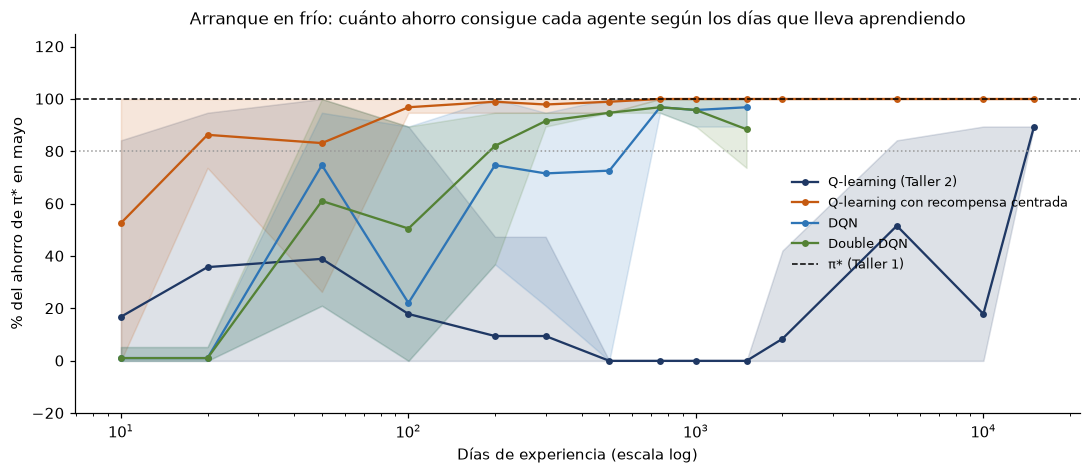

In [9]:
QLC = [entrenar_ql(mU, ENV_R, semilla=s_, centrada=True) for s_ in SEMILLAS]
ev_qlc = [resumen(repetir(c["pol"], mU, TE)) for c in QLC]
TABLA.append(fila("Q-learning con recompensa centrada (15.000 días)", ev_qlc, "qlc"))
def curva_cap(cor, ref=AHORRO_PI, es_red=True):
    ks = sorted(cor[0]["cap"]); M = np.array([[c["cap"][k] / (ref if es_red else 1) * (100 if es_red else 1) for k in ks] for c in cor])
    return np.array(ks), M
fig, ax = plt.subplots(figsize=(10, 4.4))
dias90 = {}
for j, (nom, cor, es_red, clave) in enumerate((("Q-learning (Taller 2)", QL, False, "ql"), ("Q-learning con recompensa centrada", QLC, False, "qlc"),
                                              ("DQN", DQN, True, "dqn"), ("Double DQN", DDQN, True, "ddqn"))):
    ks, M = curva_cap(cor, es_red=es_red)
    ax.plot(ks, M.mean(1) if False else M.mean(0), marker="o", ms=3.5, color=PALETA[j], label=nom)
    ax.fill_between(ks, M.min(0), M.max(0), color=PALETA[j], alpha=.15)
    llega = [k for idx, k in enumerate(ks) if (M[:, idx:] >= 80).all()]
    dias90[clave] = llega[0] if llega else None
    reg(f"{clave}_dias80", llega[0] if llega else None, (es(llega[0], 0) + " días") if llega else "no lo alcanza")
    print(f"{nom}: todas las semillas capturan ≥ 80 % del ahorro de π* desde el día {llega[0] if llega else '— (no llega)'}")
ax.axhline(100, color="black", ls="--", lw=1, label="π* (Taller 1)"); ax.axhline(80, color="#999", ls=":", lw=1)
ax.set_xscale("log"); ax.set(xlabel="Días de experiencia (escala log)", ylabel="% del ahorro de π* en mayo", ylim=(-20, 125),
                            title="Arranque en frío: cuánto ahorro consigue cada agente según los días que lleva aprendiendo")
ax.legend(frameon=False, fontsize=8.5); fig.tight_layout(); fig.savefig(FIG / "T2_arranque_frio.png"); plt.show()

## E3 · Ablación: ¿qué se rompe si se quita cada truco?

- **Sin memoria de experiencias:** cada paso entrena con las últimas 64 transiciones, consecutivas y correlacionadas.
- **Sin red objetivo:** el objetivo se calcula con la misma red que se está actualizando.
- **Sin ninguno de los dos.**

  Sin memoria de experiencias         91.7 s · ahorro mayo 0.512 % · capturado de π*  86.3 % (rango 37–100) · espera 6.0 h/día


  Sin red objetivo                    90.4 s · ahorro mayo 0.556 % · capturado de π*  93.7 % (rango 89–100) · espera 6.5 h/día


  Sin ninguno de los dos              82.1 s · ahorro mayo 0.469 % · capturado de π*  78.9 % (rango 0–100) · espera 10.1 h/día
Completo: oscilación del valor Q en los últimos 300 días = 0.0023
Sin memoria: oscilación del valor Q en los últimos 300 días = 0.0041
Sin red objetivo: oscilación del valor Q en los últimos 300 días = 0.0046
Sin ninguno: oscilación del valor Q en los últimos 300 días = 0.0108


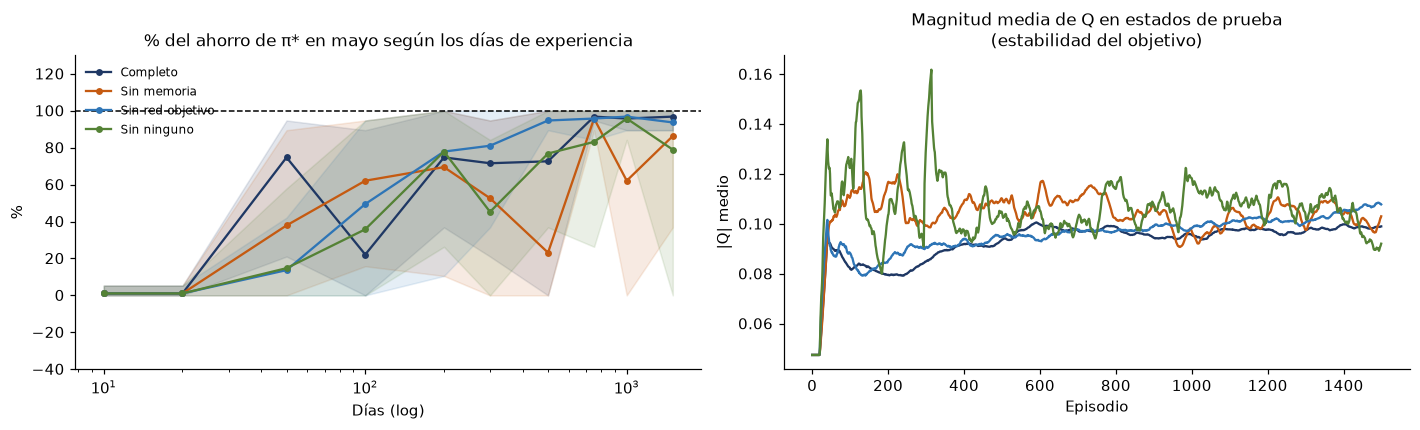

In [10]:
SINR, ev_sinr = correr_dqn("Sin memoria de experiencias", replay=False)
SINT, ev_sint = correr_dqn("Sin red objetivo", objetivo=False)
SINA, ev_sina = correr_dqn("Sin ninguno de los dos", replay=False, objetivo=False)
TABLA += [fila("DQN sin memoria de experiencias", ev_sinr, "sinr"), fila("DQN sin red objetivo", ev_sint, "sint"), fila("DQN sin ninguno", ev_sina, "sina")]
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for j, (nom, cor) in enumerate((("Completo", DQN), ("Sin memoria", SINR), ("Sin red objetivo", SINT), ("Sin ninguno", SINA))):
    ks, M = curva_cap(cor); axs[0].plot(ks, M.mean(0), marker="o", ms=3.5, color=PALETA[j], label=nom)
    axs[0].fill_between(ks, M.min(0), M.max(0), color=PALETA[j], alpha=.12)
    Qm = np.array([c["qmed"] for c in cor]); axs[1].plot(pd.Series(Qm.mean(0)).rolling(20, min_periods=1).mean(), color=PALETA[j], label=nom)
    osc = np.mean([np.std(np.diff(c["qmed"][-300:])) for c in cor]); reg(f"osc_{['dqn', 'sinr', 'sint', 'sina'][j]}", osc, es(osc, 4))
    print(f"{nom}: oscilación del valor Q en los últimos 300 días = {osc:.4f}")
axs[0].axhline(100, color="black", ls="--", lw=1); axs[0].set_xscale("log")
axs[0].set(title="% del ahorro de π* en mayo según los días de experiencia", xlabel="Días (log)", ylabel="%", ylim=(-40, 130))
axs[1].set(title="Magnitud media de Q en estados de prueba\n(estabilidad del objetivo)", xlabel="Episodio", ylabel="|Q| medio")
axs[0].legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "T3_ablacion.png"); plt.show()

## E4 · Lo que la tabla no veía: la decisión hora por hora

Con la hora exacta en el estado, la red puede decidir distinto **dentro de una misma franja**. Se dibuja la ventaja de
cada acción frente a no actuar:
- con un pico y sin carga pendiente: ventaja de **aplazar**, por hora del día;
- con una carga pendiente: ventaja de **ejecutar**, por hora y horas de espera.

Se hace para la persona paciente (λ = 0,005) y para la exigente (λ = 0,02).

  DQN · persona exigente (λ = 0,02)   90.0 s · ahorro mayo 0.475 % · capturado de π*  95.0 % (rango 81–106) · espera 4.1 h/día
Persona paciente (λ = 0,005): aplaza un pico en 18 de 18 horas de punta (de forma continua desde las 6:00); con carga pendiente ejecuta en las horas [0, 1, 2, 3, 4, 5]
Persona exigente (λ = 0,02): aplaza un pico en 7 de 18 horas de punta (de forma continua desde las 17:00); con carga pendiente ejecuta en las horas [0, 1, 2, 3, 4, 5, 9, 10, 11, 12, 13, 14, 15]
Cuenta a mano (persona exigente): el sobrecosto evitado (0.155 kWh-eq) paga como mucho 7.76 h de espera → aplazar conviene desde las 16:15; la red aplaza desde las 17:00


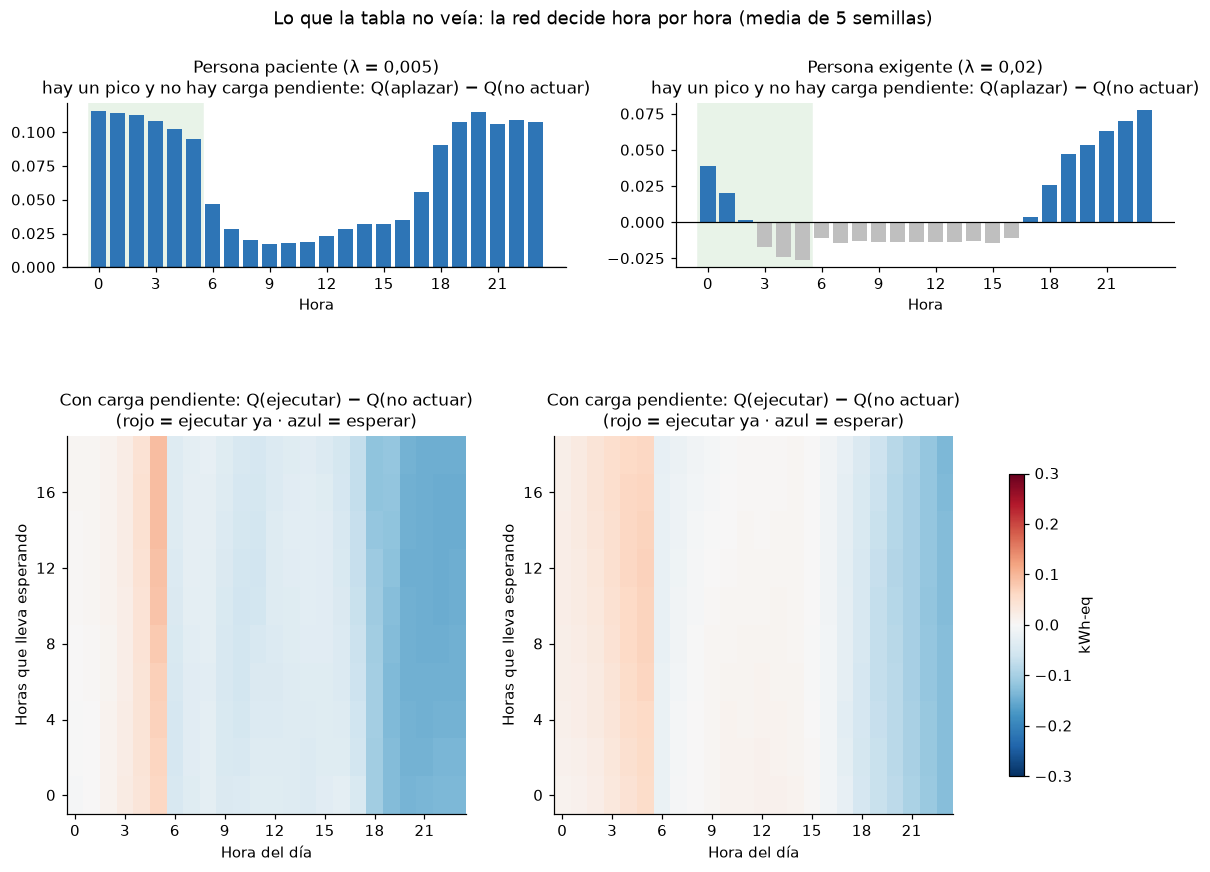

In [11]:
DQNX, ev_dqnx = correr_dqn("DQN · persona exigente (λ = 0,02)", lam=LAMBDA_EX)
TABLA.append(fila("DQN · persona exigente", ev_dqnx, "dqnx", ref=r_pix["ahorro"]))
def ventajas(red, lam_nom):
    w_alto = (np.log(1400) - MU) / SD; horas = np.arange(24)
    filas0, filas1 = [], []
    for h in horas:
        punta = float(h // 6 != 0)
        base = [np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), w_alto, w_alto, 0.0, punta]
        q0, _ = red.q(np.array([base + [0, 0, 1]])); filas0.append(q0[0, 1] - q0[0, 0])
        fila_ = []
        for hp in range(0, 19, 2):
            q1, _ = red.q(np.array([base[:2] + [0.0, 0.0, 0.0, punta] + [1, hp / 24, 0]])); fila_.append(q1[0, 2] - q1[0, 0])
        filas1.append(fila_)
    return np.array(filas0), np.array(filas1)
def tramos(hs):
    out, ini, prev = [], None, None
    for h in hs:
        if ini is None:
            ini = prev = h
        elif h == prev + 1:
            prev = h
        else:
            out.append((ini, prev)); ini = prev = h
    if ini is not None:
        out.append((ini, prev))
    return " y ".join(f"{a}:00–{b}:59" for a, b in out) if out else "ninguna"
fig, axs = plt.subplots(2, 2, figsize=(13, 8.4), gridspec_kw={"height_ratios": [1, 2.3], "hspace": 0.62, "wspace": 0.22})
for col, (lam_nom, cor) in enumerate((("paciente (λ = 0,005)", DQN), ("exigente (λ = 0,02)", DQNX))):
    V0 = np.mean([ventajas(c["red"], lam_nom)[0] for c in cor], 0); V1 = np.mean([ventajas(c["red"], lam_nom)[1] for c in cor], 0)
    axs[0, col].bar(range(24), V0, color=[("#2E75B6" if v > 0 else "#BFBFBF") for v in V0]); axs[0, col].axhline(0, color="black", lw=0.8)
    axs[0, col].axvspan(-0.5, 5.5, color="#E8F3E8", zorder=0)
    axs[0, col].set(title=f"Persona {lam_nom}\nhay un pico y no hay carga pendiente: Q(aplazar) − Q(no actuar)", xlabel="Hora", xticks=range(0, 24, 3))
    im = axs[1, col].imshow(V1.T, aspect="auto", cmap="RdBu_r", vmin=-0.3, vmax=0.3, origin="lower")
    axs[1, col].set(title="Con carga pendiente: Q(ejecutar) − Q(no actuar)\n(rojo = ejecutar ya · azul = esperar)", xlabel="Hora del día",
                    ylabel="Horas que lleva esperando", yticks=range(0, 10, 2), yticklabels=[str(x) for x in range(0, 19, 4)], xticks=range(0, 24, 3))
    tag = "pac" if col == 0 else "ex"
    punta_si = [h for h in range(6, 24) if V0[h] > 0]
    desde = next((h for h in range(6, 24) if all(V0[k] > 0 for k in range(h, 24))), None)
    ejec = [h for h in range(24) if V1[h].mean() > 0]
    reg(f"e4_{tag}_punta_aplaza", len(punta_si), es(len(punta_si), 0)); reg(f"e4_{tag}_desde", desde, f"{desde}:00" if desde is not None else "nunca")
    reg(f"e4_{tag}_ejec_horas", len(ejec), es(len(ejec), 0))
    reg(f"e4_{tag}_ejec_rango", ejec, tramos(ejec))
    print(f"Persona {lam_nom}: aplaza un pico en {len(punta_si)} de 18 horas de punta (de forma continua desde las {desde}:00); "
          f"con carga pendiente ejecuta en las horas {ejec}")
# Punto de equilibrio teórico: aplazar evita (tarifa − 1)·ΔE y cuesta λ por cada hora hasta el valle (que empieza a las 0:00)
sobre = (R_PUNTA - 1.0) * DE_KWH; umbral_h = sobre / LAMBDA_EX; hora_teo = 24 - umbral_h
reg("sobrecosto_kwh", sobre, es(sobre, 3) + " kWh-eq"); reg("e4_ex_umbral_h", umbral_h, es(umbral_h, 2) + " h")
reg("e4_ex_hora_teorica", hora_teo, f"{int(hora_teo)}:{int(round((hora_teo % 1) * 60)):02d}")
print(f"Cuenta a mano (persona exigente): el sobrecosto evitado ({sobre:.3f} kWh-eq) paga como mucho {umbral_h:.2f} h de espera → "
      f"aplazar conviene desde las {int(hora_teo)}:{int(round((hora_teo % 1) * 60)):02d}; la red aplaza desde las {CIFRAS['e4_ex_desde']['texto']}")
fig.colorbar(im, ax=axs[1, :].tolist(), shrink=0.8, label="kWh-eq")
fig.suptitle("Lo que la tabla no veía: la red decide hora por hora (media de 5 semillas)", fontsize=12)
fig.savefig(FIG / "T4_mapa_horario.png", bbox_inches="tight"); plt.show()

## Resumen, batalla final y exportación

Se exportan los pesos de la red (la semilla mediana, persona paciente) para que la consola del parcial la ejecute en la
página.

                                          Agente  Ahorro mayo (%)  Capturado de π* (%)  Espera (h/día)  Aplazamientos/día
  Q-learning recomendado (Taller 2, 15.000 días)            0.531               89.474           5.546              0.800
                                DQN (1.500 días)            0.575               96.842           6.692              0.838
                         Double DQN (1.500 días)            0.525               88.421           5.908              0.785
Q-learning con recompensa centrada (15.000 días)            0.594              100.000           7.154              0.769
                 DQN sin memoria de experiencias            0.512               86.316           5.985              0.677
                            DQN sin red objetivo            0.556               93.684           6.508              0.785
                                 DQN sin ninguno            0.469               78.947          10.115              0.654
                        

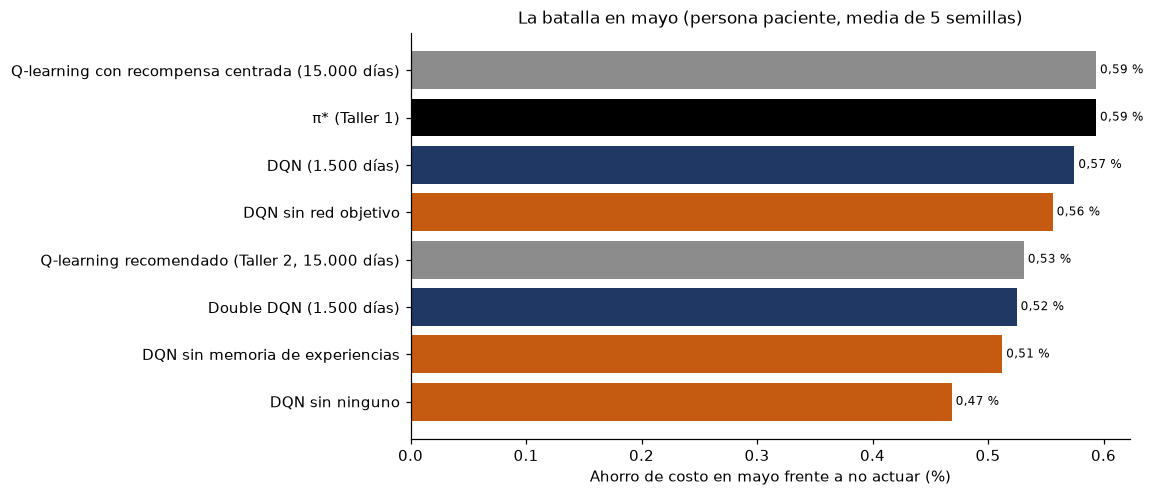

cifras.json: 84 cifras · dqn_pesos.json · figuras: ['T0_esquema_dqn.png', 'T1_aprendizaje_dqn.png', 'T2_arranque_frio.png', 'T3_ablacion.png', 'T4_mapa_horario.png', 'T5_batalla_mayo.png']


In [12]:
df_t = pd.DataFrame(TABLA); pd.set_option("display.float_format", lambda v: f"{v:,.3f}"); print(df_t.to_string(index=False))
df_t.to_csv("resumen_agentes.csv", index=False, encoding="utf-8")
fig, ax = plt.subplots(figsize=(10.5, 4.6))
nombres = ["π* (Taller 1)"] + [r_["Agente"] for r_ in TABLA if "exigente" not in r_["Agente"]]
valores = [AHORRO_PI] + [r_["Ahorro mayo (%)"] for r_ in TABLA if "exigente" not in r_["Agente"]]
orden = np.argsort(valores)
cols = ["black" if nombres[k].startswith("π*") else ("#C55A11" if "sin" in nombres[k].lower() else ("#8C8C8C" if "Q-learning" in nombres[k] else AZUL)) for k in orden]
ax.barh([nombres[k] for k in orden], [valores[k] for k in orden], color=cols)
for y_, k in enumerate(orden):
    ax.text(max(valores[k], 0), y_, f" {es(valores[k], 2)} %", va="center", fontsize=8)
ax.set_xlabel("Ahorro de costo en mayo frente a no actuar (%)"); ax.set_title("La batalla en mayo (persona paciente, media de 5 semillas)")
fig.tight_layout(); fig.savefig(FIG / "T5_batalla_mayo.png"); plt.show()

red = DQN[mediana]["red"]
Path("dqn_pesos.json").write_text(json.dumps({"rasgos": ["sin_hora", "cos_hora", "log_wh_estand", "log_wh_prev_estand", "margen_kmeans",
    "punta", "pendiente", "horas_espera_24", "nivel_alto"], "mu_logw": MU, "sd_logw": SD, "capas": {k: v.tolist() for k, v in red.p.items()},
    "lambda": LAMBDA, "semilla": SEMILLAS[mediana]}, ensure_ascii=False), encoding="utf-8")
Path("cifras.json").write_text(json.dumps({"meta": {"generado": time.strftime("%Y-%m-%d %H:%M")}, "cifras": CIFRAS},
                                          ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print(f"cifras.json: {len(CIFRAS)} cifras · dqn_pesos.json · figuras: {sorted(p.name for p in FIG.glob('T*.png'))}")